# FZP Cascade Comparison vs Element Number

This notebook plots focusing efficiency as a function of cascade depth \(N\) for three optics at the same aperture and aspect ratio (thickness / minimum feature size = 8):

- an **optimized diffractive cascade** (mean \(\pm\) std over independent random initializations)
- an **intermediate-field cascade of Fresnel zone plates** whose focal lengths coincide at the target plane: the upstream plate fills the cascade aperture and downstream radii follow the first-order cone
- a **single Fresnel zone plate** at the last-element focal length (independent of \(N\))

Load results produced by `paper/experiments/fzp_cascade_nelem_sweep.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [2]:
import sys
from pathlib import Path

repo_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(repo_root))

In [3]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams.update({'font.size': 24})

## Load sweep results

Load the stable `fzp_cascade_nelem_sweep` params and results from `paper_data/`.

In [4]:
path = repo_root / "paper_data"
params = np.load(path / f"figS5a_fzp_cascade_nelem_sweep_params.npy", allow_pickle=True).item()
results = np.load(path / f"figS5a_fzp_cascade_nelem_sweep_results.npz", allow_pickle=True)

nelems = np.asarray(results["nelems"], dtype=int).reshape(-1)
opt_efficiencies = np.asarray(results["opt_efficiencies"], dtype=float)
if opt_efficiencies.ndim == 1:
    opt_efficiencies = opt_efficiencies[np.newaxis, :]
opt_efficiencies_mean = np.nanmean(opt_efficiencies, axis=0)
opt_efficiencies_std = np.nanstd(opt_efficiencies, axis=0)
n_runs = int(results["n_runs"]) if "n_runs" in results.files else int(opt_efficiencies.shape[0])
fzp_cascade_efficiencies = np.asarray(results["fzp_cascade_efficiencies"], dtype=float).reshape(-1)
fzp_efficiency = float(np.asarray(results["fzp_efficiency"]).reshape(-1)[0])
fzp_efficiencies = np.full(nelems.shape, fzp_efficiency, dtype=float)

colors = ["C0", (0.741, 0.133, 0.031), (0.4, 0.651, 0.118)]

## Efficiency vs \(N\)

The single zone plate does not depend on cascade depth, so its efficiency is constant. The FZP cascade is deterministic and re-designed once at each \(N\). The optimized cascade is run multiple times per \(N\); the plot shows the mean with error bars of one standard deviation.

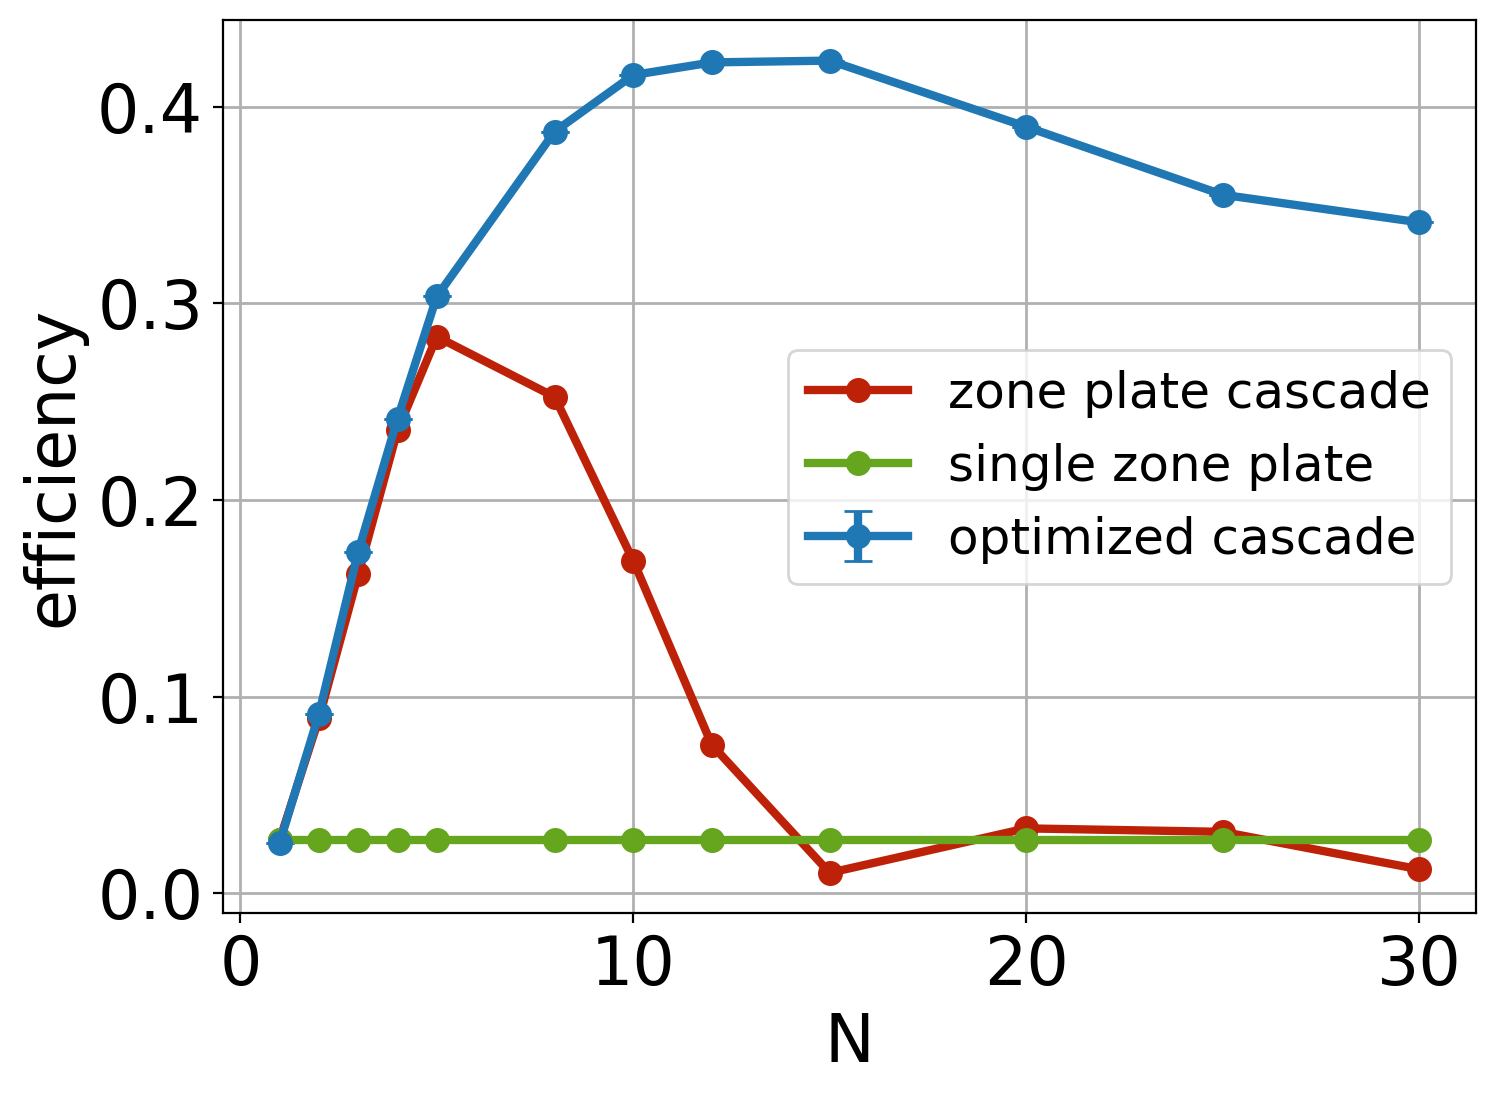

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(
    nelems, opt_efficiencies_mean, yerr=opt_efficiencies_std,
    fmt="-o", linewidth=3, markersize=8, capsize=5, color=colors[0],
    label="optimized cascade",
)
ax.plot(
    nelems, fzp_cascade_efficiencies,
    "-o", linewidth=3, markersize=8, color=colors[1], label="zone plate cascade",
)
ax.plot(
    nelems, fzp_efficiencies,
    "-o", linewidth=3, markersize=8, color=colors[2], label="single zone plate",
)
ax.set_xlabel("N")
ax.set_ylabel("efficiency")
ax.legend(fontsize=18)
ax.grid(True, linewidth=1)
fig.tight_layout()
plt.show()